# ML 08f — XGBoost Regression

This notebook trains and validates a GPU-ready XGBoost regressor using the frozen chronological split. It uses the same predictors, folds and metrics as the other ML experiments, while the 2024 final-test target remains sealed.

## Experiment safeguards

- Preprocessing is learned independently inside every chronological fold.
- The fixed model configuration is not selected using 2023 validation results.
- CUDA is used when available, with a transparent CPU fallback.
- Log-scale and back-transformed kilogram metrics match the earlier experiments.
- The 2024 test partition is never fitted, predicted or scored.

## 1. Prepare the Colab environment

This cell checks the required packages and installs XGBoost or another dependency only when it is missing from the active Colab runtime.

In [1]:
import importlib.util, subprocess, sys
packages={'pandas':'pandas>=2.0,<3','numpy':'numpy>=1.24,<3','pyarrow':'pyarrow>=14,<22','matplotlib':'matplotlib>=3.7,<4','sklearn':'scikit-learn>=1.3,<2','joblib':'joblib>=1.3,<2','xgboost':'xgboost>=2.0,<4'}
missing=[spec for module,spec in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('XGBoost experiment dependencies are available.')

XGBoost experiment dependencies are available.


## 2. Import modelling tools and detect GPU availability

The runtime is inspected for an NVIDIA GPU. XGBoost uses CUDA histogram training when available and otherwise runs the identical experiment on CPU.

In [2]:
from __future__ import annotations
import hashlib, json, shutil, subprocess, sys, time
from pathlib import Path
import joblib
import matplotlib
if 'IPython' not in sys.modules: matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBRegressor
try:
    from IPython.display import display
except ImportError:
    display=print
plt.style.use('seaborn-v0_8-whitegrid')
EXPERIMENT='xgboost'; RANDOM_STATE=42
def select_xgboost_device():
    if shutil.which('nvidia-smi') is None: return 'cpu'
    try:
        status=subprocess.run(['nvidia-smi','-L'],capture_output=True,text=True,timeout=10)
        if status.returncode!=0 or not status.stdout.strip(): return 'cpu'
        probe=XGBRegressor(n_estimators=1,max_depth=1,tree_method='hist',device='cuda',verbosity=0,random_state=RANDOM_STATE)
        probe.fit(np.array([[0.0],[1.0],[2.0],[3.0]]),np.array([0.0,1.0,2.0,3.0]))
        return 'cuda'
    except Exception as error:
        print(f'CUDA probe failed; using CPU instead: {type(error).__name__}: {error}')
        return 'cpu'
DEVICE=select_xgboost_device()
print('XGBoost device:',DEVICE)

XGBoost device: cuda


## 3. Load the frozen split and feature roles

The processed feature table, approved predictor dictionary and expanding-window folds are loaded from Drive. Only training and 2023 validation rows are exposed to this experiment.

In [3]:
def find_component_root(start:Path)->Path:
    for anchor in [start.resolve(),*start.resolve().parents]:
        for candidate in [anchor,anchor/'component - 3',anchor/'J26-DS-350'/'component - 3']:
            if (candidate/'Notebooks').is_dir() and (candidate/'src').is_dir(): return candidate.resolve()
    raise FileNotFoundError('Component 3 repository root was not found.')
IN_COLAB='google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive'); ROOT=Path('/content/drive/MyDrive/FishGuard-C3')
else: ROOT=find_component_root(Path.cwd())
DATA_PATH=ROOT/'data'/'processed'/'monthly_model_features_split.parquet'
DICTIONARY_PATH=ROOT/'outputs'/'audit'/'feature_engineering'/'feature_dictionary.csv'
FOLDS_PATH=ROOT/'outputs'/'audit'/'modelling_eda_split'/'expanding_window_cv_folds.csv'
MODEL_DIR=ROOT/'models'; EVIDENCE_DIR=ROOT/'outputs'/'audit'/'model_training'/EXPERIMENT; METRIC_DIR=ROOT/'outputs'/'metrics'/'model_training'/EXPERIMENT; PREDICTION_DIR=ROOT/'outputs'/'predictions'/'model_training'/EXPERIMENT; FIGURE_DIR=ROOT/'outputs'/'figures'/'model_training'/EXPERIMENT
for directory in [MODEL_DIR,EVIDENCE_DIR,METRIC_DIR,PREDICTION_DIR,FIGURE_DIR]: directory.mkdir(parents=True,exist_ok=True)
for path in [DATA_PATH,DICTIONARY_PATH,FOLDS_PATH]:
    if not path.is_file(): raise FileNotFoundError(f'Missing {path}.')
data=pd.read_parquet(DATA_PATH); data['month_start']=pd.to_datetime(data.month_start); dictionary=pd.read_csv(DICTIONARY_PATH); folds=pd.read_csv(FOLDS_PATH)
predictors=dictionary.loc[dictionary.role=='candidate_predictor','column'].tolist(); TARGET='target_log1p_median_catch'
train=data.loc[data.data_split.astype(str)=='train'].copy(); validation=data.loc[data.data_split.astype(str)=='validation'].copy(); test_rows=int((data.data_split.astype(str)=='test').sum())
numeric=[column for column in predictors if pd.api.types.is_numeric_dtype(train[column])]; categorical_features=[column for column in predictors if column not in numeric]
source_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print('Train:',len(train),'Validation:',len(validation),'Sealed test:',test_rows,'Predictors:',len(predictors))

Mounted at /content/drive
Train: 8197 Validation: 792 Sealed test: 941 Predictors: 80


## 4. Build the leakage-safe XGBoost pipeline

Imputation and encoding remain inside the pipeline. Low-rate boosting, row and feature subsampling, child-weight constraints and L1/L2 penalties provide a strong but regularized tabular model.

In [4]:
numeric_pipeline=Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True))])
categorical_pipeline=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
preprocessor=ColumnTransformer([('numeric',numeric_pipeline,numeric),('categorical',categorical_pipeline,categorical_features)],verbose_feature_names_out=False)
estimator=XGBRegressor(objective='reg:absoluteerror',eval_metric='mae',n_estimators=1000,learning_rate=.025,max_depth=6,min_child_weight=8,subsample=.85,colsample_bytree=.8,gamma=.02,reg_alpha=.05,reg_lambda=2.0,tree_method='hist',device=DEVICE,n_jobs=-1,random_state=RANDOM_STATE)
pipeline=Pipeline([('preprocess',preprocessor),('model',estimator)])
configuration={'objective':'reg:absoluteerror','eval_metric':'mae','n_estimators':1000,'learning_rate':0.025,'max_depth':6,'min_child_weight':8,'subsample':0.85,'colsample_bytree':0.8,'gamma':0.02,'reg_alpha':0.05,'reg_lambda':2.0,'tree_method':'hist','device':DEVICE,'random_state':42}
print(configuration)

{'objective': 'reg:absoluteerror', 'eval_metric': 'mae', 'n_estimators': 1000, 'learning_rate': 0.025, 'max_depth': 6, 'min_child_weight': 8, 'subsample': 0.85, 'colsample_bytree': 0.8, 'gamma': 0.02, 'reg_alpha': 0.05, 'reg_lambda': 2.0, 'tree_method': 'hist', 'device': 'cuda', 'random_state': 42}


## 5. Run expanding-window cross-validation

Three chronological folds measure transfer to later periods without future leakage. The same log and kilogram metrics make the result directly comparable with all earlier models.

In [5]:
def metrics(y_true_log,y_pred_log):
    y_true_log=np.asarray(y_true_log,float); y_pred_log=np.asarray(y_pred_log,float)
    true_kg=np.clip(np.expm1(y_true_log),0,None); pred_kg=np.clip(np.expm1(np.clip(y_pred_log,0,None)),0,None)
    return {'log_mae':mean_absolute_error(y_true_log,y_pred_log),'log_rmse':mean_squared_error(y_true_log,y_pred_log)**.5,'log_median_ae':median_absolute_error(y_true_log,y_pred_log),'log_r2':r2_score(y_true_log,y_pred_log),'kg_mae':mean_absolute_error(true_kg,pred_kg),'kg_rmse':mean_squared_error(true_kg,pred_kg)**.5,'kg_median_ae':median_absolute_error(true_kg,pred_kg),'kg_bias':float(np.mean(pred_kg-true_kg))}
cv_rows=[]
for fold in folds.itertuples(index=False):
    fold_train=train.loc[train.month_start<=pd.Timestamp(fold.train_end)]; fold_valid=train.loc[(train.month_start>=pd.Timestamp(fold.validation_start))&(train.month_start<=pd.Timestamp(fold.validation_end))]
    fitted=clone(pipeline); started=time.perf_counter(); fitted.fit(fold_train[predictors],fold_train[TARGET]); elapsed=time.perf_counter()-started; prediction=fitted.predict(fold_valid[predictors])
    cv_rows.append({'fold_id':int(fold.fold_id),'model':EXPERIMENT,'train_rows':len(fold_train),'validation_rows':len(fold_valid),'fit_seconds':elapsed,**metrics(fold_valid[TARGET],prediction)})
    print(f'Completed fold {int(fold.fold_id)} on {DEVICE}')
cv=pd.DataFrame(cv_rows); cv.to_csv(METRIC_DIR/'cv_metrics.csv',index=False)
display(cv)

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [18:43:37] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Completed fold 1 on cuda
Completed fold 2 on cuda
Completed fold 3 on cuda


,fold_id,model,train_rows,validation_rows,fit_seconds,log_mae,log_rmse,log_median_ae,log_r2,kg_mae,kg_rmse,kg_median_ae,kg_bias
0,1,xgboost,6816,733,1.844404,0.762427,1.028772,0.581395,0.412492,88.413234,263.994529,17.237535,-65.743194
1,2,xgboost,7549,272,1.789670,0.869426,1.174032,0.680983,0.048786,83.446546,287.774125,26.960322,-37.190525
2,3,xgboost,7821,376,1.821589,0.860942,1.134985,0.631288,0.349629,178.891073,527.355850,27.061670,-129.322022


## 6. Fit on all training data and evaluate 2023

The unchanged pipeline is fitted on the complete development-training period and evaluated once on the untouched 2023 validation partition before its predictions and model are saved.

In [6]:
started=time.perf_counter(); fitted_pipeline=clone(pipeline).fit(train[predictors],train[TARGET]); fit_seconds=time.perf_counter()-started
validation_prediction=fitted_pipeline.predict(validation[predictors]); validation_result={'model':EXPERIMENT,'fit_seconds':fit_seconds,**metrics(validation[TARGET],validation_prediction)}
validation_metrics=pd.DataFrame([validation_result]); validation_metrics.to_csv(METRIC_DIR/'validation_metrics.csv',index=False)
predictions=validation[['month_start','spatial_cell_id','species_model','gear_model',TARGET,'target_median_catch_weight_kg']].copy().rename(columns={'target_median_catch_weight_kg':'actual_kg'})
predictions['prediction_log']=validation_prediction; predictions['prediction_kg']=np.expm1(predictions.prediction_log.clip(lower=0)); predictions['residual_log']=predictions[TARGET]-predictions.prediction_log
predictions.to_csv(PREDICTION_DIR/'validation_predictions.csv',index=False)
summary=pd.DataFrame([{'model':EXPERIMENT,'cv_log_mae_mean':cv.log_mae.mean(),'cv_log_mae_std':cv.log_mae.std(),'cv_kg_mae_mean':cv.kg_mae.mean(),**validation_result}])
summary.to_csv(METRIC_DIR/'experiment_summary.csv',index=False)
MODEL_PATH=MODEL_DIR/f'{EXPERIMENT}_development_pipeline.joblib'; joblib.dump(fitted_pipeline,MODEL_PATH); model_sha256=hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()
display(summary)

,model,cv_log_mae_mean,cv_log_mae_std,cv_kg_mae_mean,fit_seconds,log_mae,log_rmse,log_median_ae,log_r2,kg_mae,kg_rmse,kg_median_ae,kg_bias
0,xgboost,0.830932,0.059479,116.916951,1.907474,0.827303,1.115753,0.659646,0.40303,128.903443,464.028118,21.029014,-91.099664


## 7. Diagnose validation behaviour and feature importance

Residual plots show systematic error, temporal scores reveal stability, and repeated permutation importance measures the contribution of original predictors on unseen 2023 data.

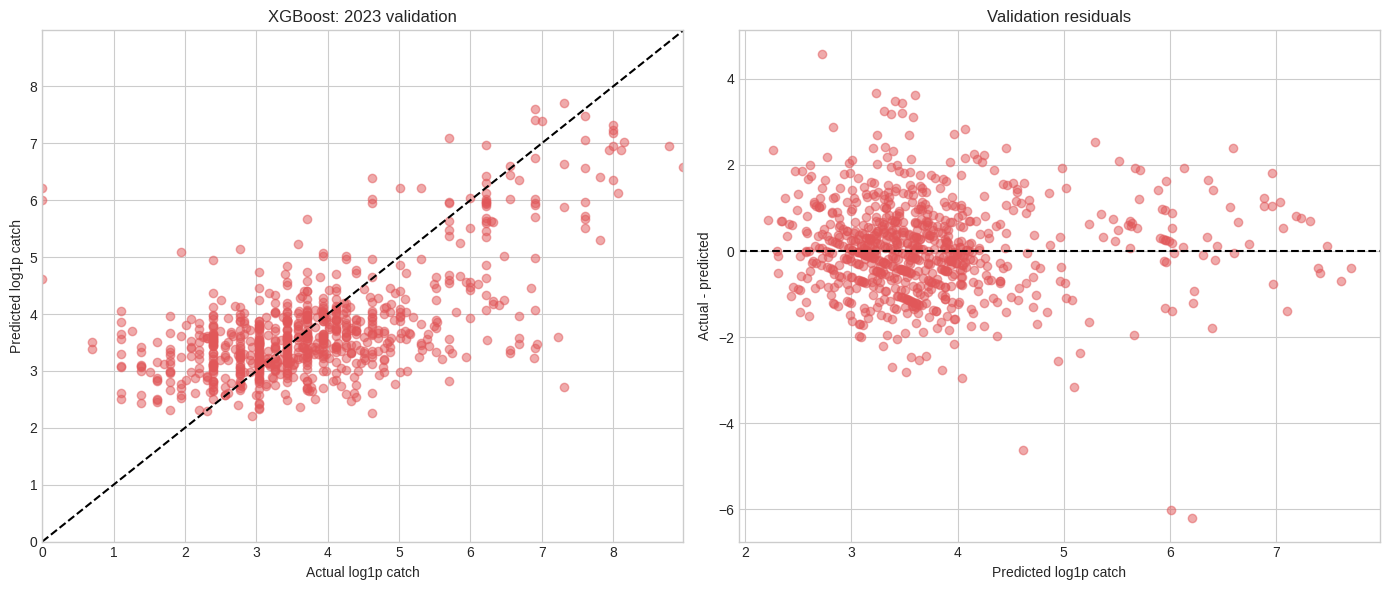

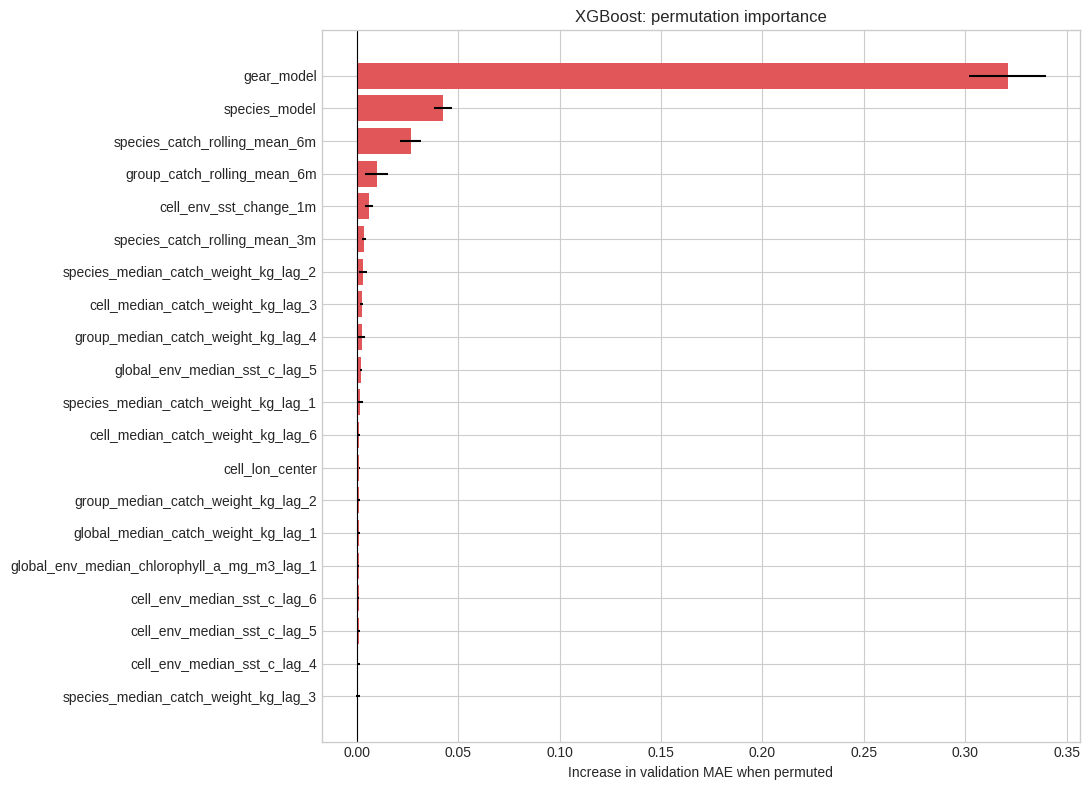

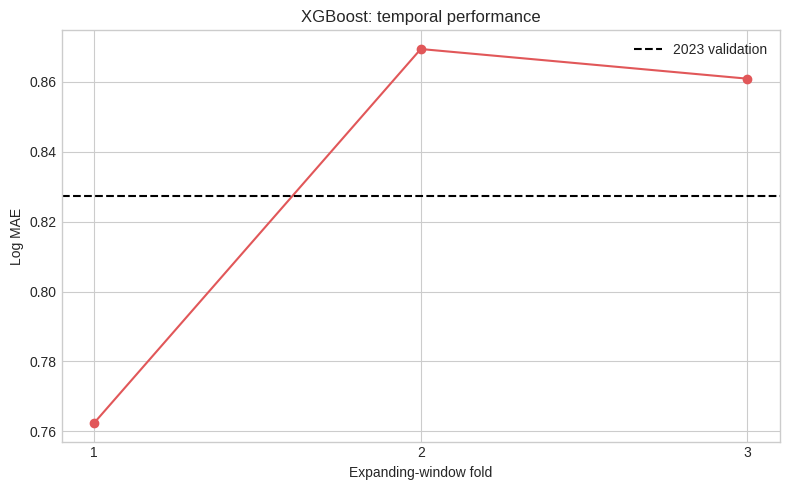

,feature,importance_mean,importance_std
1,gear_model,0.320777,0.018738
0,species_model,0.042482,0.004403
33,species_catch_rolling_mean_6m,0.026558,0.005023
30,group_catch_rolling_mean_6m,0.009938,0.005585
68,cell_env_sst_change_1m,0.006125,0.001908
32,species_catch_rolling_mean_3m,0.003556,0.000905
11,species_median_catch_weight_kg_lag_2,0.003214,0.001895
18,cell_median_catch_weight_kg_lag_3,0.002564,0.000697
7,group_median_catch_weight_kg_lag_4,0.002440,0.001602
61,global_env_median_sst_c_lag_5,0.002291,0.000577


In [7]:
importance_jobs=1 if DEVICE=='cuda' else -1
importance=permutation_importance(fitted_pipeline,validation[predictors],validation[TARGET],scoring='neg_mean_absolute_error',n_repeats=5,random_state=RANDOM_STATE,n_jobs=importance_jobs)
importance_table=pd.DataFrame({'feature':predictors,'importance_mean':importance.importances_mean,'importance_std':importance.importances_std}).sort_values('importance_mean',ascending=False)
importance_table.to_csv(METRIC_DIR/'validation_permutation_importance.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,6))
axes[0].scatter(predictions[TARGET],predictions.prediction_log,alpha=.5,color='#e15759'); limits=[min(predictions[TARGET].min(),predictions.prediction_log.min()),max(predictions[TARGET].max(),predictions.prediction_log.max())]; axes[0].plot(limits,limits,'--',color='black'); axes[0].set_xlim(limits); axes[0].set_ylim(limits); axes[0].set_xlabel('Actual log1p catch'); axes[0].set_ylabel('Predicted log1p catch'); axes[0].set_title('XGBoost: 2023 validation')
axes[1].scatter(predictions.prediction_log,predictions.residual_log,alpha=.5,color='#e15759'); axes[1].axhline(0,color='black',linestyle='--'); axes[1].set_xlabel('Predicted log1p catch'); axes[1].set_ylabel('Actual - predicted'); axes[1].set_title('Validation residuals')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'validation_diagnostics.png',dpi=200,bbox_inches='tight'); plt.show()
top=importance_table.head(20).sort_values('importance_mean'); fig,ax=plt.subplots(figsize=(11,8)); ax.barh(top.feature,top.importance_mean,xerr=top.importance_std,color='#e15759'); ax.axvline(0,color='black',linewidth=.8); ax.set_xlabel('Increase in validation MAE when permuted'); ax.set_title('XGBoost: permutation importance'); fig.tight_layout(); fig.savefig(FIGURE_DIR/'permutation_importance.png',dpi=200,bbox_inches='tight'); plt.show()
fig,ax=plt.subplots(figsize=(8,5)); ax.plot(cv.fold_id,cv.log_mae,marker='o',color='#e15759'); ax.axhline(validation_result['log_mae'],color='black',linestyle='--',label='2023 validation'); ax.set_xticks(cv.fold_id); ax.set_xlabel('Expanding-window fold'); ax.set_ylabel('Log MAE'); ax.set_title('XGBoost: temporal performance'); ax.legend(); fig.tight_layout(); fig.savefig(FIGURE_DIR/'temporal_performance.png',dpi=200,bbox_inches='tight'); plt.show()
display(importance_table.head(20))

## 8. Verify and document the XGBoost experiment

Final assertions verify split integrity, target exclusion, finite predictions and model-file integrity before saving audit findings and the reproducibility manifest.

In [8]:
checks=pd.DataFrame([
 {'check':'test excluded','passed':len(train)+len(validation)+test_rows==len(data),'detail':f'{test_rows} sealed rows'},
 {'check':'target excluded','passed':TARGET not in predictors and not any(x.startswith('target_') for x in predictors),'detail':f'{len(predictors)} predictors'},
 {'check':'pipeline preprocessing','passed':isinstance(fitted_pipeline,Pipeline),'detail':'imputation/encoding inside pipeline'},
 {'check':'three folds','passed':cv.fold_id.nunique()==3,'detail':str(sorted(cv.fold_id.unique()))},
 {'check':'finite validation predictions','passed':np.isfinite(validation_prediction).all(),'detail':f'{len(validation_prediction)} predictions'},
 {'check':'model hash','passed':hashlib.sha256(MODEL_PATH.read_bytes()).hexdigest()==model_sha256,'detail':MODEL_PATH.name}])
assert checks.passed.all(); checks.to_csv(EVIDENCE_DIR/'experiment_checks.csv',index=False)
findings=pd.DataFrame([{'finding':'Model','result':'XGBoost Regression'},{'finding':'Training device','result':DEVICE},{'finding':'Mean expanding-window log MAE','result':f'{cv.log_mae.mean():.4f}'},{'finding':'2023 validation log MAE','result':f"{validation_result['log_mae']:.4f}"},{'finding':'2023 validation kg MAE','result':f"{validation_result['kg_mae']:.2f} kg"},{'finding':'2023 validation kg bias','result':f"{validation_result['kg_bias']:.2f} kg"},{'finding':'Test status','result':'2024 target sealed and unused'}])
findings.to_csv(EVIDENCE_DIR/'experiment_findings.csv',index=False)
manifest={'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),'runtime':'Google Colab' if IN_COLAB else 'Local Windows','experiment':EXPERIMENT,'configuration':configuration,'input':DATA_PATH.name,'input_sha256':source_sha256,'train_rows':len(train),'validation_rows':len(validation),'sealed_test_rows':test_rows,'test_target_used':False,'predictors':predictors,'model_file':MODEL_PATH.name,'model_sha256':model_sha256,'metrics':sorted(p.name for p in METRIC_DIR.glob('*.csv')),'predictions':sorted(p.name for p in PREDICTION_DIR.glob('*.csv')),'figures':sorted(p.name for p in FIGURE_DIR.glob('*.png'))}
with (EVIDENCE_DIR/'experiment_manifest.json').open('w',encoding='utf-8') as f: json.dump(manifest,f,indent=2)
display(checks); display(findings)

,check,passed,detail
0,test excluded,True,941 sealed rows
1,target excluded,True,80 predictors
2,pipeline preprocessing,True,imputation/encoding inside pipeline
3,three folds,True,"[np.int64(1), np.int64(2), np.int64(3)]"
4,finite validation predictions,True,792 predictions
5,model hash,True,xgboost_development_pipeline.joblib


,finding,result
0,Model,XGBoost Regression
1,Training device,cuda
2,Mean expanding-window log MAE,0.8309
3,2023 validation log MAE,0.8273
4,2023 validation kg MAE,128.90 kg
5,2023 validation kg bias,-91.10 kg
6,Test status,2024 target sealed and unused


## Viva interpretation

XGBoost builds trees sequentially so that each new tree corrects errors left by the existing ensemble. Its regularization and subsampling reduce overfitting, while chronological evaluation determines whether the improvement transfers to future periods rather than only fitting historical observations.